# DINOv2: Learning Robust Visual Features without Supervision

**Paper:** M. Oquab, T. Darcet, T. Moutakanni, H. V. Vo, M. Szafraniec, V. Khalidov, P. Fernandez, D. Haziza, F. Massa, A. El-Nouby, M. Assran, N. Ballas, W. Galvez, R. Beber, A. Joulin, H. Jégou, J. Mairal, P. Labatut, A. Joulin, and P. Bojanowski, "DINOv2: Learning Robust Visual Features without Supervision," *Transactions on Machine Learning Research (TMLR)*, 2024. [arXiv:2304.07193](https://arxiv.org/abs/2304.07193)

**Summary:** DINOv2 trains ViT backbones with self-supervised distillation at scale, introducing register tokens and LayerScale to obtain universal visual features that transfer without fine-tuning to tasks ranging from depth estimation to semantic segmentation.

> 📄 **Paper:** Oquab et al. (2024). DINOv2: Learning Robust Visual Features without Supervision. TMLR 2024 · Darcet et al. (2024). Vision Transformers Need Registers. ICLR 2024.
> 🔗 **Link:** <https://arxiv.org/abs/2304.07193>
> 🧩 **Implementation:** `hale_core/nn/vision/vit/dino.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> PE["PatchEmbed 14×14 → 16×16 = 256 patches"]:::stage
  PE --> TOK["[CLS] + register tokens + patches · + pos-embed"]:::stage --> ENC["L × block (LayerScale)"]:::stage --> NORM["LN"]:::block
  NORM --> POOL["pooled = CLS · patch_tokens drop registers"]:::block --> OUT
  subgraph SSL["DINOv2 training (not in the backbone)"]
    direction LR
    T["teacher (EMA)"] --> L["DINO + iBOT + KoLeo losses"]:::block
    S["student"] --> L
  end
  ENC -.-> SSL
  OUT["BackboneOutput<br/>pooled_output (B, D)<br/>patch_tokens (B, N, D)<br/>feature_maps [(B, D, H/p, W/p)]"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Overview

```
Input Image [B, 3, H, W]
        │
        ▼  PatchEmbed (Conv2d, patch_size=14)  ← DINOv2 uses p=14, not p=16
Patches [B, N, D]   N = (H/14)² = 256 for 224px
        │
        ▼  Build token sequence:
           [CLS] token prepended          → 1 token
           patch tokens                  → N tokens
           → cat → [B, N+1, D]
           + positional embedding (CLS + patches only)
        │
        ▼  Insert register tokens AFTER positional embedding:
           [CLS | reg₁ | reg₂ | reg₃ | reg₄ | P₁ | P₂ | ... | P_N]
           Total length: 1 + 4 + N = N+5
        │
        ▼  ┌─────────────────────────────────────────────────────────┐
           │  DINOBlock × depth                                       │
           │  ┌─────────────────────────────────────────────────────┐ │
           │  │  x = x + LayerScale_γ₁ · DINOAttn(LN(x))           │ │
           │  │  x = x + LayerScale_γ₂ · MLP(LN(x))                │ │
           │  │  DINOAttn: Flash Attention (F.scaled_dot_product)    │ │
           │  │  LayerScale: per-channel γ, init=1e-5               │ │
           │  └─────────────────────────────────────────────────────┘ │
           └─────────────────────────────────────────────────────────┘
        │
        ▼  Final LayerNorm
        │
        ▼  DISCARD register tokens (positions 1..4)
        │
        ├──► pooled_output = x[:, 0]                  (CLS)
        └──► patch_tokens  = x[:, 1+n_reg:]           (N patch tokens, reg discarded)
             feature_maps  = reshape → [B, D, H/14, W/14]
```

### DINO v1 vs DINOv2 — What Changed?
| Feature | DINO v1 | DINOv2 |
|---------|---------|--------|
| Register tokens | No | Yes (4 per image) |
| LayerScale | No | Yes (γ init=1e-5) |
| Flash Attention | No | Yes (PyTorch ≥2.0) |
| Patch size | 16 | 14 |
| Training loss | DINO (self-distillation) | DINO + iBOT + KoLeo |
| Data curation | ImageNet | Large curated 142M dataset |

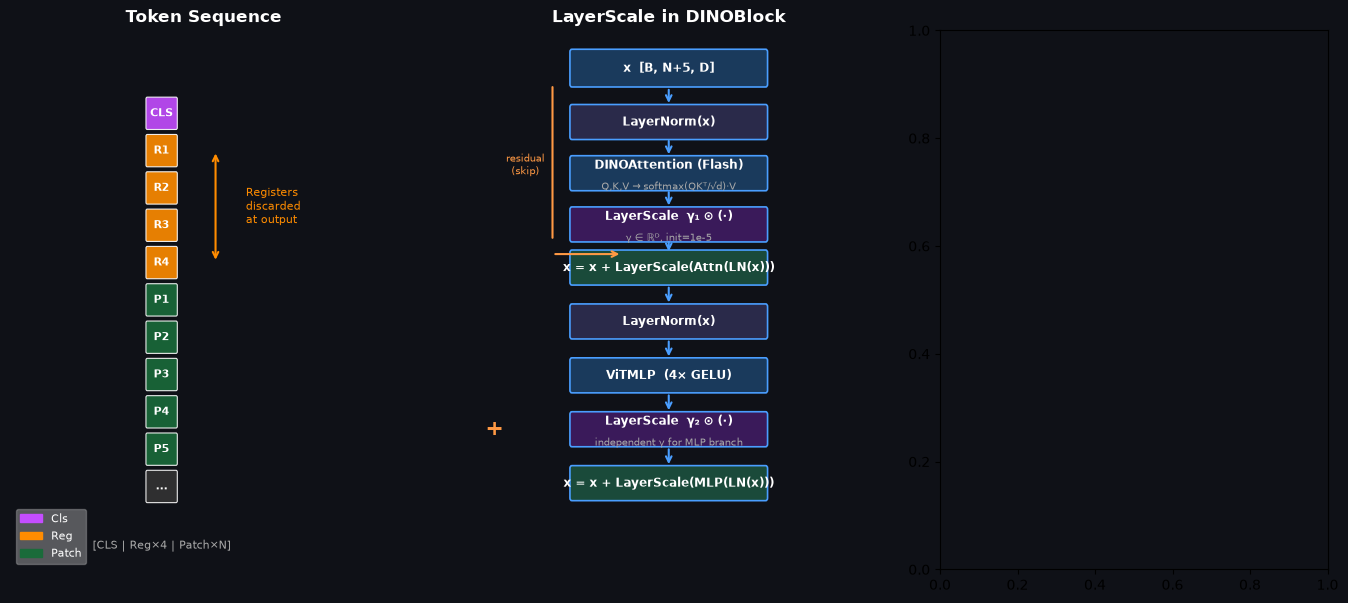

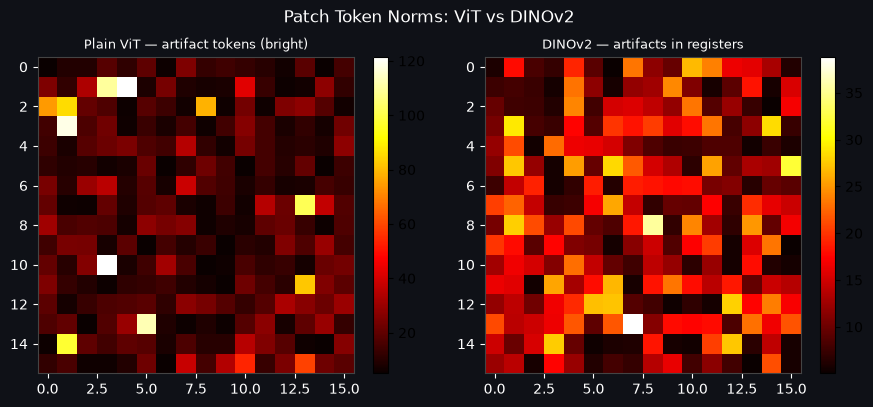

<Figure size 640x480 with 0 Axes>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

fig = plt.figure(figsize=(17, 7))
fig.patch.set_facecolor('#0f1117')

# ── Left panel: Token sequence diagram ──────────────────────────────────────
ax1 = fig.add_subplot(1, 3, 1)
ax1.set_facecolor('#0f1117')
ax1.set_xlim(-0.5, 11)
ax1.set_ylim(-1, 12)
ax1.axis('off')
ax1.set_title('Token Sequence', color='white', fontsize=12, fontweight='bold')

TOKEN_H = 0.7
TOKEN_W = 0.85
COLORS = {'cls': '#c44dff', 'reg': '#ff8c00', 'patch': '#1a6b3a'}

def draw_token(ax, x, y, label, color, width=0.85):
    b = FancyBboxPatch((x - width/2, y - TOKEN_H/2), width, TOKEN_H,
                        boxstyle='round,pad=0.04', facecolor=color,
                        edgecolor='white', linewidth=0.8, alpha=0.9)
    ax.add_patch(b)
    ax.text(x, y, label, ha='center', va='center', color='white',
            fontsize=8, fontweight='bold')

# DINO sequence: CLS + 4 regs + patches
tokens = [('CLS', COLORS['cls'])] + \
         [(f'R{i}', COLORS['reg']) for i in range(1, 5)] + \
         [(f'P{i}', COLORS['patch']) for i in range(1, 6)] + \
         [('...', '#333')]

for i, (label, color) in enumerate(tokens):
    y = 10 - i * 0.9
    draw_token(ax1, 4, y, label, color)

# Bracket for registers
ax1.annotate('', xy=(5.6, 10 - 0.9), xytext=(5.6, 10 - 0.9*4),
             arrowprops=dict(arrowstyle='<->', color='#ff8c00', lw=1.5))
ax1.text(6.5, 10 - 0.9*2.5, 'Registers\ndiscarded\nat output',
         ha='left', va='center', color='#ff8c00', fontsize=8)

# Legend
legend_items = [mpatches.Patch(color=v, label=k.title()) for k, v in COLORS.items()]
ax1.legend(handles=legend_items, loc='lower left', framealpha=0.3,
           labelcolor='white', fontsize=8)

ax1.text(4, -0.5, '[CLS | Reg×4 | Patch×N]', ha='center', color='#aaa', fontsize=8)

# ── Middle panel: LayerScale diagram ─────────────────────────────────────────
ax2 = fig.add_subplot(1, 3, 2)
ax2.set_facecolor('#0f1117')
ax2.set_xlim(0, 10)
ax2.set_ylim(0, 10)
ax2.axis('off')
ax2.set_title('LayerScale in DINOBlock', color='white', fontsize=12, fontweight='bold')

def box(ax, x, y, w, h, txt, sub='', fc='#1a3a5c'):
    p = FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle='round,pad=0.05',
                        facecolor=fc, edgecolor='#4a9eff', linewidth=1.2)
    ax.add_patch(p)
    ax.text(x, y + (0.15 if sub else 0), txt, ha='center', va='center',
            color='white', fontsize=8.5, fontweight='bold')
    if sub:
        ax.text(x, y-0.25, sub, ha='center', va='center', color='#aaa', fontsize=7)

def arr(ax, x, y1, y2):
    ax.annotate('', xy=(x, y2+0.05), xytext=(x, y1-0.05),
                arrowprops=dict(arrowstyle='->', color='#4a9eff', lw=1.5))

# Input
box(ax2, 5, 9.3, 5, 0.6, 'x  [B, N+5, D]', '', '#1a3a5c')
arr(ax2, 5, 9.0, 8.55)
box(ax2, 5, 8.3, 5, 0.55, 'LayerNorm(x)', '', '#2a2a4a')
arr(ax2, 5, 8.05, 7.6)
box(ax2, 5, 7.35, 5, 0.55, 'DINOAttention (Flash)', 'Q,K,V → softmax(QKᵀ/√d)·V', '#1a3a5c')
arr(ax2, 5, 7.1, 6.65)
# LayerScale box highlighted
box(ax2, 5, 6.4, 5, 0.55, 'LayerScale  γ₁ ⊙ (·)', 'γ ∈ ℝᴰ, init=1e-5', '#3a1a5a')
# Residual
ax2.annotate('', xy=(5, 5.85), xytext=(5, 6.13),
             arrowprops=dict(arrowstyle='->', color='#4a9eff', lw=1.5))
ax2.annotate('', xy=(2, 6.1), xytext=(2, 9.0),
             arrowprops=dict(arrowstyle='-', color='#ff9944', lw=1.5))
ax2.annotate('', xy=(3.8, 5.85), xytext=(2, 5.85),
             arrowprops=dict(arrowstyle='->', color='#ff9944', lw=1.5))
ax2.text(1.3, 7.5, 'residual\n(skip)', ha='center', va='center', color='#ff9944', fontsize=7.5)
box(ax2, 5, 5.6, 5, 0.55, 'x = x + LayerScale(Attn(LN(x)))', '', '#1a4a3a')

arr(ax2, 5, 5.33, 4.85)
box(ax2, 5, 4.6, 5, 0.55, 'LayerNorm(x)', '', '#2a2a4a')
arr(ax2, 5, 4.33, 3.85)
box(ax2, 5, 3.6, 5, 0.55, 'ViTMLP  (4× GELU)', '', '#1a3a5c')
arr(ax2, 5, 3.33, 2.85)
box(ax2, 5, 2.6, 5, 0.55, 'LayerScale  γ₂ ⊙ (·)', 'independent γ for MLP branch', '#3a1a5a')
ax2.text(0.5, 2.6, '+', ha='center', va='center', color='#ff9944', fontsize=16, fontweight='bold')
arr(ax2, 5, 2.33, 1.85)
box(ax2, 5, 1.6, 5, 0.55, 'x = x + LayerScale(MLP(LN(x)))', '', '#1a4a3a')

# ── Right: Attention comparison DINO vs plain ViT ────────────────────────────
ax3 = fig.add_subplot(1, 3, 3)
ax3.set_facecolor('#0f1117')

rng = np.random.default_rng(7)
# Simulate: ViT without registers — some patch tokens develop high-norm artifacts
grid = 16
N = grid * grid
# Patch token norms — some outliers
norms_vit = np.abs(rng.standard_normal(N)) * 15 + 5
artifact_idx = rng.choice(N, 12, replace=False)
norms_vit[artifact_idx] += rng.uniform(50, 100, 12)  # artifact tokens
norms_vit_img = norms_vit.reshape(grid, grid)

# DINO: artifacts absorbed by register tokens, patch norms more uniform
norms_dino = np.abs(rng.standard_normal(N)) * 12 + 5
norms_dino_img = norms_dino.reshape(grid, grid)

fig2, (axA, axB) = plt.subplots(1, 2, figsize=(9, 4))
fig2.patch.set_facecolor('#0f1117')
fig2.suptitle('Patch Token Norms: ViT vs DINOv2', color='white', fontsize=12)
for axi, data, title in zip([axA, axB],
                              [norms_vit_img, norms_dino_img],
                              ['Plain ViT — artifact tokens (bright)', 'DINOv2 — artifacts in registers']):
    axi.set_facecolor('#0f1117')
    im = axi.imshow(data, cmap='hot', interpolation='nearest')
    plt.colorbar(im, ax=axi, fraction=0.046)
    axi.set_title(title, color='white', fontsize=9)
    axi.tick_params(colors='white')
    for sp in axi.spines.values():
        sp.set_edgecolor('#444')

plt.tight_layout()

plt.show()

plt.figure(fig.number)
plt.tight_layout()

plt.show()

## 3. Key ideas

## Key Innovations

### 1. Register Tokens — Eliminating Artifact Tokens

**Problem:** Large ViTs trained with DINO develop high-norm "artifact" tokens in patch positions that correspond to smooth background regions (sky, grass, uniform textures). These tokens accumulate global image statistics and disrupt local feature quality.

**Solution:** Introduce $R$ learnable register tokens (default $R=4$), inserted between CLS and the patch tokens **after** positional embedding:
$$\text{sequence} = [x_{cls}, \; r_1, r_2, r_3, r_4, \; x_1, \ldots, x_N]$$

Register tokens are **not** given positional embeddings (they represent global context, not spatial positions). At inference, they are simply **discarded** from the output.

**Result:** Artifact behavior moves to the register tokens, which are designed to hold global info. Patch tokens retain clean local spatial features.

### 2. LayerScale — Stabilising Deep Transformers

Introduced in CaiT (Touvron et al., 2021) and adopted by DINOv2:

$$x \leftarrow x + \gamma_1 \odot \text{Attention}(\text{LN}(x))$$
$$x \leftarrow x + \gamma_2 \odot \text{MLP}(\text{LN}(x))$$

where $\gamma_1, \gamma_2 \in \mathbb{R}^D$ are **per-channel learnable parameters** initialised at $10^{-5}$.

**Why it works:** Near $\gamma \approx 0$, residuals start near-zero, preventing gradient explosion in the first steps of training. As training progresses, $\gamma$ grows, allowing residuals to contribute more. This is a form of adaptive skip-connection strength.

### 3. Flash Attention — Memory-Efficient Scaled Dot-Product

PyTorch 2.0 provides `F.scaled_dot_product_attention`, which:
- Fuses softmax + matmul into a single CUDA kernel (Flash Attention algorithm)
- Avoids materialising the full $N \times N$ attention matrix in HBM
- Gives **~2× speedup** and **~10× memory reduction** for long sequences
- Result is numerically equivalent to standard attention

```python
# Standard attention (materialises [B,H,N,N] attention matrix)
attn = softmax(q @ k.T / sqrt(d))
out  = attn @ v  # O(N²) memory

# Flash Attention (fused, O(N) memory)
out = F.scaled_dot_product_attention(q, k, v, dropout_p=p)
```

## Module Walkthrough

### LayerScale
```python
class LayerScale(nn.Module):
    def __init__(self, dim, init_value=1e-5):
        # γ: per-channel scalar, starts near zero
        self.gamma = nn.Parameter(init_value * torch.ones(dim))

    def forward(self, x):   # x: [B, N, D]
        return x * self.gamma  # element-wise broadcast over D
```

### DINOBlock — Full Residual with LayerScale
```python
class DINOBlock(nn.Module):
    def forward(self, x, return_attn=False):
        attn_out, attn_weights = self.attn(self.norm1(x), return_attn=return_attn)
        x = x + self.ls1(attn_out)          # scaled residual
        x = x + self.ls2(self.mlp(self.norm2(x)))
        return x, attn_weights
```

### Forward — Register token insertion and removal
```python
def forward(self, x):
    patches = self.patch_embed(x)                # [B, N, D]
    cls = self.cls_token.expand(B, -1, -1)       # [B, 1, D]
    tokens = torch.cat([cls, patches], dim=1)    # [B, N+1, D]
    tokens = tokens + self.pos_embed             # positional info for CLS+patches

    # Insert 4 register tokens (no positional embedding for them)
    regs   = self.register_tokens.expand(B, -1, -1)  # [B, 4, D]
    tokens = torch.cat([tokens[:, :1],   # CLS
                         regs,            # 4 registers
                         tokens[:, 1:]], dim=1)  # patches

    for blk in self.blocks:
        tokens, attn = blk(tokens)
    tokens = self.norm(tokens)

    # Discard register tokens (positions 1..4)
    pooled   = tokens[:, 0]           # CLS
    patches  = tokens[:, 1+n_reg:]    # N patch tokens
    return BackboneOutput(pooled, patches, [spatial_reshape(patches)])
```

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/vit/dino.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>vit/dino.py</code></summary>

```text
DINOv2 Vision Transformer Backbone
=====================================

Paper: "DINOv2: Learning Robust Visual Features without Supervision"
       (Oquab et al., 2023) — https://arxiv.org/abs/2304.07193

Architecture Overview
---------------------
DINOv2 builds on ViT with three key improvements for self-supervised training:

1. Register Tokens
   Large ViTs develop high-norm artifact tokens in background regions.  DINOv2
   introduces n_register learnable tokens inserted AFTER the CLS token.  Registers
   absorb global image statistics (background, repetitive textures), freeing patch
   tokens to carry semantically meaningful local features.  At inference they are
   discarded — only CLS and patch tokens form the output.

2. LayerScale (Caron et al., 2021 — CaiT)
   A per-channel learnable scalar γ initialised at a small value (1e-5 for large
   models) multiplied onto each residual output:
       x = x + γ · Attention(LN(x))
   This prevents deep networks from exploding gradients during early training by
   making residuals near-zero initially, then letting γ grow naturally.

3. Flash Attention (F.scaled_dot_product_attention)
   Uses PyTorch 2.0's fused kernel when available.  Falls back to manual attention
   on older versions.  No numerical difference — the fused kernel is just faster.

Variants registered
-------------------
  dino_vit_small  — 384-dim, 6 heads,  12 layers, patch=14, 4 registers
  dino_vit_base   — 768-dim, 12 heads, 12 layers, patch=14, 4 registers
  dino_vit_large  — 1024-dim, 16 heads, 24 layers, patch=14, 4 registers
  dino_vit_giant  — 1536-dim, 24 heads, 40 layers, patch=14, 4 registers  ← DINOv2-g
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### Shared building blocks from `vit/vit.py` used by this family: `PatchEmbed`, `ViTMLP`, `_trunc_normal_`

In [5]:
def _trunc_normal_(tensor: torch.Tensor, std: float = 0.02) -> torch.Tensor:
    """Truncated normal init at ±2σ — standard for ViT weight init."""
    with torch.no_grad():
        # Box–Muller via normal + clamp, then rescale to correct distribution
        nn.init.trunc_normal_(tensor, mean=0.0, std=std, a=-2 * std, b=2 * std)
    return tensor


class PatchEmbed(nn.Module):
    """Convert an image into non-overlapping patch embeddings.

    Uses a single Conv2d with kernel_size=stride=patch_size, which is
    mathematically equivalent to splitting the image into patches and applying
    a shared linear projection to each, but is faster due to BLAS layout.

    Args:
        img_size:   Assumed square input size (used to pre-compute N_patches).
        patch_size: Side length of each square patch (e.g. 16 or 14).
        in_chans:   Input channels (3 for RGB).
        embed_dim:  Projected dimension D.
    """

    def __init__(
        self,
        img_size: int = 224,
        patch_size: int = 16,
        in_chans: int = 3,
        embed_dim: int = 768,
    ) -> None:
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.grid_size = img_size // patch_size          # e.g. 14 for 224/16
        self.num_patches = self.grid_size ** 2

        # A single strided convolution performs the patch extraction + linear projection
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
        _trunc_normal_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, C, H, W] → [B, D, H/p, W/p] → [B, N, D]
        x = self.proj(x)                                 # [B, D, G, G]
        x = x.flatten(2).transpose(1, 2)                # [B, N, D]
        return x


class ViTMLP(nn.Module):
    """Two-layer GELU MLP, expand ratio 4× (standard ViT FFN).

    Structure: Linear(D → 4D) → GELU → Dropout → Linear(4D → D) → Dropout
    """

    def __init__(self, dim: int, mlp_ratio: float = 4.0, drop: float = 0.0) -> None:
        super().__init__()
        hidden = int(dim * mlp_ratio)
        self.fc1 = nn.Linear(dim, hidden)
        self.act = nn.GELU()
        self.drop1 = nn.Dropout(drop)
        self.fc2 = nn.Linear(hidden, dim)
        self.drop2 = nn.Dropout(drop)

        _trunc_normal_(self.fc1.weight)
        _trunc_normal_(self.fc2.weight)
        nn.init.zeros_(self.fc1.bias)
        nn.init.zeros_(self.fc2.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.drop1(self.act(self.fc1(x)))
        return self.drop2(self.fc2(x))

### 4.2 `vit/dino.py`, definition by definition

**`LayerScale`** - Per-channel learned scale applied to a residual branch.

In [6]:
class LayerScale(nn.Module):
    """Per-channel learned scale applied to a residual branch.

    Initialised at `init_value` (≈1e-5 for large models) so residuals start
    near zero.  The scale is learned and grows during training, allowing the
    network to gradually increase the residual contribution.

    Reference: "Going Deeper with Image Transformers" (Touvron et al., 2021)
               https://arxiv.org/abs/2103.17239
    """

    def __init__(self, dim: int, init_value: float = 1e-5) -> None:
        super().__init__()
        # Scalar per output channel; starts small to dampen residuals initially
        self.gamma = nn.Parameter(init_value * torch.ones(dim))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * self.gamma

**`DINOAttention`** - Multi-head self-attention with optional PyTorch 2.0 fused kernel.

In [7]:
class DINOAttention(nn.Module):
    """Multi-head self-attention with optional PyTorch 2.0 fused kernel.

    When torch.nn.functional.scaled_dot_product_attention is available (PyTorch
    ≥ 2.0), uses the fused Flash Attention kernel for ~2× speedup on long
    sequences.  Falls back to manual attention on older versions.

    Args:
        dim:       Token dimension D.
        num_heads: Number of attention heads H.
        attn_drop: Dropout probability on attention weights (ignored for flash attn).
        proj_drop: Dropout probability on output projection.
    """

    def __init__(
        self,
        dim: int,
        num_heads: int = 8,
        attn_drop: float = 0.0,
        proj_drop: float = 0.0,
    ) -> None:
        super().__init__()
        assert dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.attn_drop_p = attn_drop

        self.in_proj = nn.Linear(dim, dim * 3, bias=True)
        self.out_proj = nn.Linear(dim, dim, bias=True)
        self.proj_drop = nn.Dropout(proj_drop)

        # Check once at init whether fused kernel is available
        self._use_flash = hasattr(F, "scaled_dot_product_attention")

        _trunc_normal_(self.in_proj.weight)
        _trunc_normal_(self.out_proj.weight)
        nn.init.zeros_(self.in_proj.bias)
        nn.init.zeros_(self.out_proj.bias)

    def forward(
        self, x: torch.Tensor, return_attn: bool = False
    ) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
        B, N, D = x.shape
        H = self.num_heads

        qkv = self.in_proj(x).reshape(B, N, 3, H, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)                          # each [B, H, N, d]

        if self._use_flash and not return_attn:
            # Fused Flash Attention — no explicit attention matrix materialised
            # dropout_p only applies during training; set 0.0 at eval
            drop_p = self.attn_drop_p if self.training else 0.0
            x = F.scaled_dot_product_attention(q, k, v, dropout_p=drop_p)
            attn_weights = None
        else:
            # Manual attention (needed when return_attn=True for visualisation)
            attn = (q @ k.transpose(-2, -1)) * self.scale
            attn = F.softmax(attn, dim=-1)
            if self.training and self.attn_drop_p > 0:
                attn = F.dropout(attn, p=self.attn_drop_p)
            attn_weights = attn if return_attn else None
            x = attn @ v

        x = x.transpose(1, 2).reshape(B, N, D)
        return self.proj_drop(self.out_proj(x)), attn_weights

**`DINOBlock`** - DINOv2 transformer block: pre-norm + LayerScale on both branches.

In [8]:
class DINOBlock(nn.Module):
    """DINOv2 transformer block: pre-norm + LayerScale on both branches.

    Residual:
        x = x + LayerScale(Attention(LN(x)))
        x = x + LayerScale(MLP(LN(x)))
    """

    def __init__(
        self,
        dim: int,
        num_heads: int,
        mlp_ratio: float = 4.0,
        attn_drop: float = 0.0,
        mlp_drop: float = 0.0,
        ls_init: float = 1e-5,
    ) -> None:
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = DINOAttention(dim, num_heads=num_heads, attn_drop=attn_drop, proj_drop=mlp_drop)
        self.ls1 = LayerScale(dim, init_value=ls_init)

        self.norm2 = nn.LayerNorm(dim)
        self.mlp = ViTMLP(dim, mlp_ratio=mlp_ratio, drop=mlp_drop)
        self.ls2 = LayerScale(dim, init_value=ls_init)

    def forward(
        self, x: torch.Tensor, return_attn: bool = False
    ) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
        attn_out, attn_weights = self.attn(self.norm1(x), return_attn=return_attn)
        x = x + self.ls1(attn_out)
        x = x + self.ls2(self.mlp(self.norm2(x)))
        return x, attn_weights

**`DINOv2Backbone`** - DINOv2 ViT backbone with register tokens and LayerScale.

In [9]:
class DINOv2Backbone(BaseVisionBackbone):
    """DINOv2 ViT backbone with register tokens and LayerScale.

    Output:
      - pooled_output:  CLS token embedding [B, D]
      - patch_tokens:   Patch tokens (register tokens discarded) [B, N, D]
      - feature_maps:   Patch tokens as spatial grid [B, D, H/p, W/p]

    Args:
        embed_dim:     Token dimension D.
        depth:         Number of transformer blocks.
        num_heads:     Attention heads.
        patch_size:    Patch side length (default 14 for DINOv2).
        n_register:    Number of register tokens (default 4).
        use_cls:       Whether to use a CLS token (True by default).
                       If False, mean-pools all patch tokens as pooled_output.
        ls_init:       LayerScale initial value (1e-5 for large, 1.0 disables).
        mlp_ratio:     FFN expansion ratio.
        return_all_attn: Cache attention maps from all blocks.
    """

    arch_name: str = "dino"

    def __init__(
        self,
        img_size: int = 224,
        in_chans: int = 3,
        embed_dim: int = 768,
        depth: int = 12,
        num_heads: int = 12,
        patch_size: int = 14,
        n_register: int = 4,
        use_cls: bool = True,
        ls_init: float = 1e-5,
        mlp_ratio: float = 4.0,
        attn_drop: float = 0.0,
        drop_rate: float = 0.0,
        return_all_attn: bool = False,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate, out_indices=out_indices)
        self.embed_dim = embed_dim
        self.patch_size = patch_size
        self.n_register = n_register
        self.use_cls = use_cls
        self.depth = depth
        self.return_all_attn = return_all_attn
        self.feature_dims = [embed_dim]

        self.patch_embed = PatchEmbed(img_size, patch_size, in_chans, embed_dim)
        num_patches = self.patch_embed.num_patches

        # CLS token and positional embedding (pos emb covers CLS + patches only, not registers)
        if use_cls:
            self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        else:
            self.cls_token = None

        # Register tokens — extra learnable tokens inserted after CLS
        self.register_tokens = nn.Parameter(torch.zeros(1, n_register, embed_dim))

        # Positional embedding for CLS + patches (registers share no positional info — design choice)
        n_cls = 1 if use_cls else 0
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + n_cls, embed_dim))
        self.pos_drop = nn.Dropout(drop_rate)

        self.blocks = nn.ModuleList([
            DINOBlock(embed_dim, num_heads, mlp_ratio=mlp_ratio, attn_drop=attn_drop, mlp_drop=drop_rate, ls_init=ls_init)
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)

        self._init_weights()

    def _init_weights(self) -> None:
        if self.cls_token is not None:
            _trunc_normal_(self.cls_token)
        _trunc_normal_(self.register_tokens)
        _trunc_normal_(self.pos_embed)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze embeddings and the first `stage` blocks."""
        self.patch_embed.requires_grad_(False)
        if self.cls_token is not None:
            self.cls_token.requires_grad_(False)
        self.register_tokens.requires_grad_(False)
        self.pos_embed.requires_grad_(False)
        for i in range(min(stage + 1, self.depth)):
            self.blocks[i].requires_grad_(False)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        B = x.shape[0]

        # 1. Patch embedding
        patches = self.patch_embed(x)                    # [B, N, D]

        # 2. Build token sequence: [CLS, patches] then add positional embedding
        if self.use_cls:
            cls = self.cls_token.expand(B, -1, -1)       # [B, 1, D]
            tokens = torch.cat([cls, patches], dim=1)    # [B, 1+N, D]
        else:
            tokens = patches                             # [B, N, D]

        tokens = self.pos_drop(tokens + self.pos_embed)

        # 3. Insert register tokens AFTER positional embedding (they don't have positions)
        regs = self.register_tokens.expand(B, -1, -1)   # [B, n_reg, D]
        if self.use_cls:
            # Insert registers between CLS and patches: [CLS, reg..., patches]
            tokens = torch.cat([tokens[:, :1], regs, tokens[:, 1:]], dim=1)
        else:
            # No CLS: [reg..., patches]
            tokens = torch.cat([regs, tokens], dim=1)

        # 4. Transformer blocks
        attn_maps: list[torch.Tensor] = []
        for blk in self.blocks:
            tokens, attn = blk(tokens, return_attn=self.return_all_attn)
            if self.return_all_attn and attn is not None:
                attn_maps.append(attn)

        tokens = self.norm(tokens)

        # 5. Extract outputs — discard register tokens
        if self.use_cls:
            n_prefix = 1 + self.n_register              # CLS + registers
            pooled = tokens[:, 0]                       # CLS token [B, D]
            patches_out = tokens[:, n_prefix:]          # patch tokens [B, N, D]
        else:
            pooled = tokens[:, self.n_register:].mean(dim=1)  # mean pool over patches
            patches_out = tokens[:, self.n_register:]

        G = self.patch_embed.grid_size
        feat_map = patches_out.transpose(1, 2).reshape(B, self.embed_dim, G, G)

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=patches_out,
            feature_maps=[feat_map],
            attentions=attn_maps if self.return_all_attn else None,
        )

**`DINOViTSmall`** - DINOv2 ViT-S/14 — 22M params.

In [10]:
@register_vision_backbone("dino_vit_small")
class DINOViTSmall(DINOv2Backbone):
    """DINOv2 ViT-S/14 — 22M params."""
    arch_name = "dino_vit_small"
    feature_dims = [384]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 384)
        kwargs.setdefault("depth", 12)
        kwargs.setdefault("num_heads", 6)
        kwargs.setdefault("patch_size", 14)
        kwargs.setdefault("n_register", 4)
        kwargs.setdefault("ls_init", 1e-5)
        super().__init__(**kwargs)

**`DINOViTBase`** - DINOv2 ViT-B/14 — 86M params.

In [11]:
@register_vision_backbone("dino_vit_base")
class DINOViTBase(DINOv2Backbone):
    """DINOv2 ViT-B/14 — 86M params."""
    arch_name = "dino_vit_base"
    feature_dims = [768]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 768)
        kwargs.setdefault("depth", 12)
        kwargs.setdefault("num_heads", 12)
        kwargs.setdefault("patch_size", 14)
        kwargs.setdefault("n_register", 4)
        kwargs.setdefault("ls_init", 1e-5)
        super().__init__(**kwargs)

**`DINOViTLarge`** - DINOv2 ViT-L/14 — 307M params.

In [12]:
@register_vision_backbone("dino_vit_large")
class DINOViTLarge(DINOv2Backbone):
    """DINOv2 ViT-L/14 — 307M params."""
    arch_name = "dino_vit_large"
    feature_dims = [1024]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 1024)
        kwargs.setdefault("depth", 24)
        kwargs.setdefault("num_heads", 16)
        kwargs.setdefault("patch_size", 14)
        kwargs.setdefault("n_register", 4)
        kwargs.setdefault("ls_init", 1e-5)
        super().__init__(**kwargs)

**`DINOViTGiant`** - DINOv2 ViT-G/14 — 1.1B params.  The flagship DINOv2 model.

In [13]:
@register_vision_backbone("dino_vit_giant")
class DINOViTGiant(DINOv2Backbone):
    """DINOv2 ViT-G/14 — 1.1B params.  The flagship DINOv2 model."""
    arch_name = "dino_vit_giant"
    feature_dims = [1536]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 1536)
        kwargs.setdefault("depth", 40)
        kwargs.setdefault("num_heads", 24)
        kwargs.setdefault("patch_size", 14)
        kwargs.setdefault("n_register", 4)
        kwargs.setdefault("ls_init", 1e-5)
        super().__init__(**kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [14]:
DEMOS = {'dino_vit_small': 22.1}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['dino_vit_base', 'dino_vit_giant', 'dino_vit_large', 'dino_vit_small']



dino_vit_small  (DINOViTSmall)
  pooled_output : (2, 384)   embed_dim = 384
  patch_tokens  : (2, 256, 384)
  feature_map 0: (2, 384, 16, 16)   stride 14


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [15]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
dino_vit_small           21.63M     22.02M    22.1M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [16]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

dino_vit_small: loss 1.9835 | 175/175 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [17]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

dino_vit_small: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

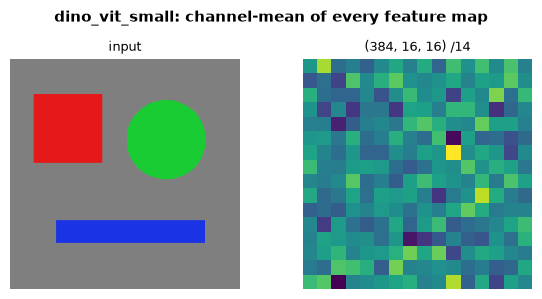

In [18]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [19]:
import sys
import numpy as np
import matplotlib.pyplot as plt

Parameters:       21,630,336
Embed dim:        384
Register tokens:  4
Patch size:       14

pooled_output:  torch.Size([1, 384])
patch_tokens:   torch.Size([1, 256, 384])
feature_maps:   torch.Size([1, 384, 16, 16])

[Register tokens were inserted during forward but discarded from output]


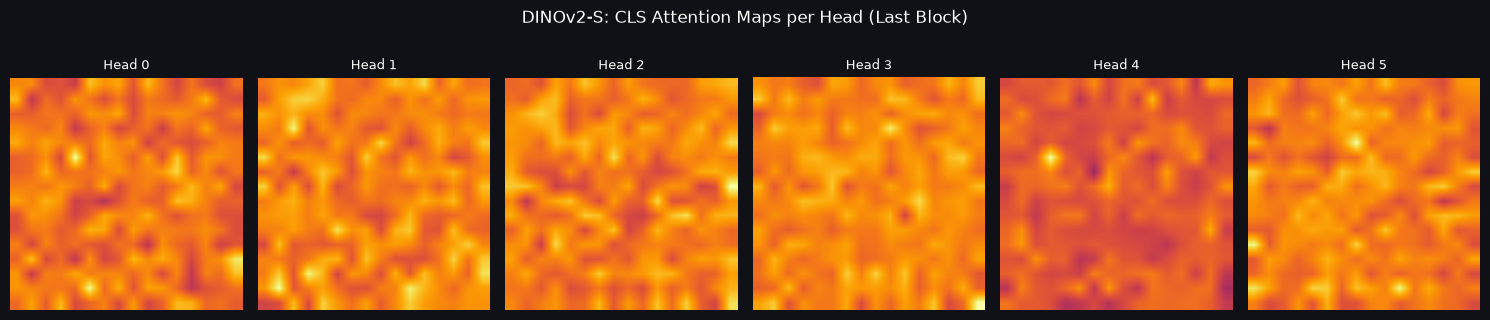

Note: each head focuses on different semantic regions (object parts, background, edges).


In [20]:
import sys

import torch

backbone = build_vision_backbone('dino_vit_small', img_size=224, return_all_attn=True)
backbone.eval()
print(f'Parameters:       {backbone.num_parameters():,}')
print(f'Embed dim:        {backbone.embed_dim}')
print(f'Register tokens:  {backbone.n_register}')
print(f'Patch size:       {backbone.patch_size}')  # 14 for DINOv2

x = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    out = backbone(x)

print(f'\npooled_output:  {out.pooled_output.shape}')   # [1, 384]
print(f'patch_tokens:   {out.patch_tokens.shape}')      # [1, 256, 384] (16×16 grid at p=14)
print(f'feature_maps:   {out.feature_maps[0].shape}')   # [1, 384, 16, 16]
print(f'\n[Register tokens were inserted during forward but discarded from output]')

# Visualise DINOv2-style attention maps with high-quality patches
fig, axes = plt.subplots(1, 6, figsize=(15, 3.5))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('DINOv2-S: CLS Attention Maps per Head (Last Block)', color='white', fontsize=12)

# Last block attention, CLS row, patch columns
last_attn  = out.attentions[-1][0]   # [H, N+1+n_reg, N+1+n_reg]
n_reg = backbone.n_register
n_total = last_attn.shape[-1]
# CLS attends to patches (skip register columns)
# token order: CLS=0, reg=1..4, patches=5..
cls_to_patches = last_attn[:, 0, 1+n_reg:].reshape(last_attn.shape[0], 16, 16)
cls_to_patches = cls_to_patches.numpy()

for i, ax in enumerate(axes):
    ax.set_facecolor('#0f1117')
    im = ax.imshow(cls_to_patches[i], cmap='inferno', interpolation='bilinear', vmin=0)
    ax.set_title(f'Head {i}', color='white', fontsize=9)
    ax.axis('off')

plt.tight_layout()

plt.show()
print('Note: each head focuses on different semantic regions (object parts, background, edges).')

## References

### Primary
1. M. Oquab et al., "DINOv2: Learning Robust Visual Features without Supervision," *TMLR 2024*. [arXiv:2304.07193](https://arxiv.org/abs/2304.07193)
2. T. Darcet et al., "Vision Transformers Need Registers," *ICLR 2024*. [arXiv:2309.16588](https://arxiv.org/abs/2309.16588) — register tokens paper

### Related Works
3. M. Caron et al., "Emerging Properties in Self-Supervised Vision Transformers," *ICCV 2021*. [arXiv:2104.14294](https://arxiv.org/abs/2104.14294) — DINO v1
4. H. Touvron et al., "Going Deeper with Image Transformers," *ICCV 2021*. [arXiv:2103.17239](https://arxiv.org/abs/2103.17239) — LayerScale (CaiT)
5. T. Dao et al., "FlashAttention-2: Faster Attention with Better Parallelism and Work Partitioning," *ICLR 2024*. [arXiv:2307.08691](https://arxiv.org/abs/2307.08691)
6. A. Dosovitskiy et al., "An Image is Worth 16×16 Words," *ICLR 2021*. [arXiv:2010.11929](https://arxiv.org/abs/2010.11929) — ViT
7. J. Assran et al., "Self-Supervised Learning from Images with a Joint-Embedding Predictive Architecture," *CVPR 2023*. [arXiv:2301.08243](https://arxiv.org/abs/2301.08243) — I-JEPA